# Dimensionality Reduction using PCA

**Aim:** To implement Principal Component Analysis (PCA) and reduce the number of features of a dataset.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## 2. Load dataset

In [2]:
data = load_iris()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
print(df.head())
print("Shape of data:", X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
Shape of data: (150, 4)


## 3. Standardize the data
PCA is affected by scale of features so we scale first.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


## 4. Apply PCA (all components first)

In [4]:
pca_full = PCA()
pca_full.fit(X_scaled)

print("Explained variance ratio:", pca_full.explained_variance_ratio_)
print("Cumulative variance:", np.cumsum(pca_full.explained_variance_ratio_))

Explained variance ratio: [0.72962445 0.22850762 0.03668922 0.00517871]
Cumulative variance: [0.72962445 0.95813207 0.99482129 1.        ]


## 5. Scree plot and cumulative variance

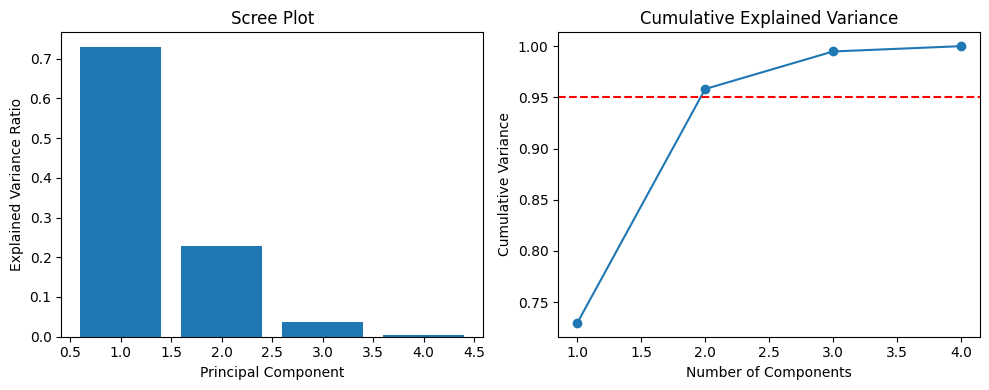

In [5]:
var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.bar(range(1, len(var)+1), var)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")

plt.subplot(1,2,2)
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.title("Cumulative Explained Variance")

plt.tight_layout()
plt.show()

## 6. Reduce to 2 components

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)
print("Variance kept:", sum(pca.explained_variance_ratio_))

Original shape: (150, 4)
Reduced shape: (150, 2)
Variance kept: 0.9581320720000166


## 7. Plot the reduced data

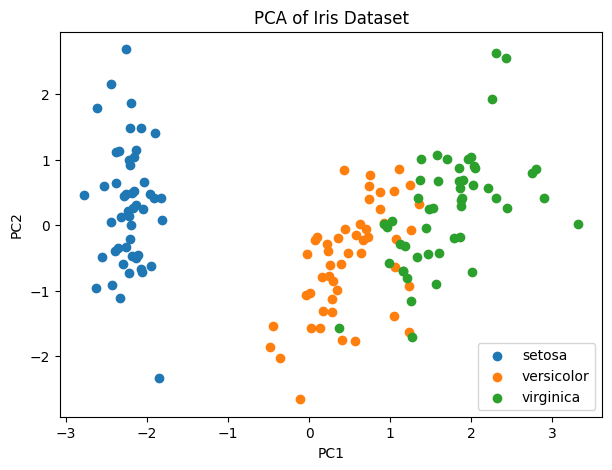

In [7]:
plt.figure(figsize=(7,5))
for i, name in enumerate(data.target_names):
    plt.scatter(X_pca[y==i, 0], X_pca[y==i, 1], label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Iris Dataset")
plt.legend()
plt.show()

## 8. Contribution of original features to each PC

In [8]:
components = pd.DataFrame(pca.components_, columns=data.feature_names, index=['PC1','PC2'])
print(components)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1           0.521066         -0.269347           0.580413          0.564857
PC2           0.377418          0.923296           0.024492          0.066942


## 9. Compare model accuracy before and after PCA

In [9]:
# without PCA
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
acc_before = accuracy_score(y_test, model.predict(X_test))

# with PCA
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_pca, y, test_size=0.3, random_state=42)
model2 = LogisticRegression()
model2.fit(X_train2, y_train2)
acc_after = accuracy_score(y_test2, model2.predict(X_test2))

print("Accuracy with 4 features:", acc_before)
print("Accuracy with 2 PCA components:", acc_after)

Accuracy with 4 features: 1.0
Accuracy with 2 PCA components: 0.9111111111111111


## Conclusion
PCA reduced the Iris dataset from 4 features to 2 principal components while keeping about 95.8% of the variance. The classes are still clearly visible in the PC1-PC2 plot. Accuracy dropped a little (1.0 to about 0.91) because some information was lost, but the model works with half the features, so PCA is useful for reducing dimensions.